In [1]:
import numpy as np
import librosa as lr
import scipy as sp
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import HTML

from filters import *

In [2]:
y, sr = lr.load("../data/audio/s05.wav", sr=None)

Text(0, 0.5, 'level [dB]')

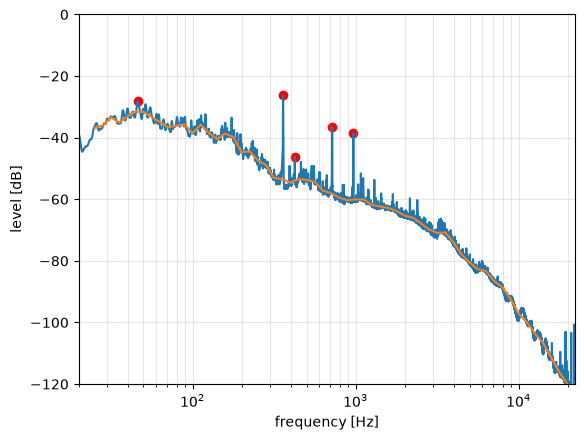

In [3]:
nperseg = 2**16

# spectrum and decibel conversion
f, P = sp.signal.welch(
    y, fs=sr, window="hann", nperseg=nperseg, scaling="spectrum", nfft=4 * nperseg
)
db = 10 * np.log10(2 * P + 1e-20)

# find peaks
peaks, _ = sp.signal.find_peaks(db, prominence=10, height=-60)
peak_freq, peak_db = quad_interp(f, db, peaks)
peak_width = sp.signal.peak_widths(P, peaks, rel_height=0.5)
peak_df = pl.DataFrame(
    {
        "idx": peaks,
        "peak_spec_freq": f[peaks],
        "peak_spec_db": db[peaks],
        "peak_spec_pow": P[peaks],
        "peak_freq": peak_freq,
        "peak_db": peak_db,
        "peak_spec_width": peak_width[0] * np.diff(f)[0] / (sr / nperseg),
    }
)

# fit the floor as medians across log-spaced bins
bin_centers = 1000 * 10 ** (np.arange(-32, 28) / 20)
# edges halfway (in log) between the centers, which are 1/20 decade apart
bins = bin_centers / 10**0.025
floor = sp.stats.binned_statistic(f, db, statistic="median", bins=bins)[0]

# plot spectrum
plt.semilogx(f, db, label="spectrum")

# plot found peaks
plt.scatter(f[peaks], db[peaks], color="red")

# plot the "floor"
plt.semilogx(bin_centers[:-1], floor, label="floor")

plt.xlim(20, sr / 2)
plt.ylim(-120, 0)
plt.grid(True, which="both", alpha=0.3)
plt.xlabel("frequency [Hz]")
plt.ylabel("level [dB]")

the situation is a bit different so we will split it into three parts:

fit the tones, fit the curve with spectral tilt filters, and fit the extra "bumps" on the residuals with bell SVFs

In [4]:
y, sr = lr.load(
    "../data/audio/s05.wav", sr=None, mono=False
)

nperseg = 2**16
bin_centers = 1000 * 10 ** (np.arange(-32, 28) / 20)
# edges halfway (in log) between the centers, which are 1/20 decade apart
bins = bin_centers / 10**0.025

# spectrum of both channels at once, shape (2, freqs)
f, P = sp.signal.welch(
    y, fs=sr, window="hann", nperseg=nperseg, scaling="spectrum", nfft=4 * nperseg
)
db = 10 * np.log10(2 * P + 1e-20)

# tones: need one peak freq but separate gains
found = [sp.signal.find_peaks(db[ch], prominence=12, height=-60)[0] for ch in range(2)]


# merge peaks closer than 8 points apart

# first sort and find all unique ones
thresh = 8
peaks = []
for k in np.sort(np.concatenate(found)):
    if not peaks or k - peaks[-1] > thresh:
        peaks.append(k)


# then get levels from each channel at the max
def tone_level(d, k):
    # channel max near the peak
    j = k - thresh + np.argmax(d[k - thresh : k + thresh + 1])
    # if we are at edge then peak missing :(,
    # read raw value for gain, omit freq
    if abs(j - k) == thresh:
        return np.nan, d[k]
    # interpolate as above
    return quad_interp(f, d, j)


tones = []
for k in peaks:
    freqs, gains = [], []
    for ch in range(2):
        # is there a peak found in the channel
        near = found[ch][np.abs(found[ch] - k) <= thresh]
        if len(near):
            # interpolate as above at loudest nearby point
            freq, gain = quad_interp(f, db[ch], near[np.argmax(db[ch][near])])
            freqs.append(freq)
        else:
            # peak missing in this channel :( read "peak" value for gain, omit freq
            gain = db[ch][k]
        gains.append(gain)

    tones.append({"freq": np.mean(freqs), "gainL": gains[0], "gainR": gains[1]})

# export the tones
tone_df = pl.DataFrame(tones)
# low peaks should just be bell filter bumps
tone_df = tone_df.filter(pl.col("freq") > 100)
tone_df.write_csv("../data/room-05-tones.csv")


# recompute the spectrum as "density", shape (2, freqs)
grid = 20 * 2 ** (np.arange(0, 24 * np.log2(20_000 / 20)) / 24)
smooth = lambda d: np.array(
    [
        np.median(d[(f_d >= c * 2 ** (-1 / 12)) & (f_d <= c * 2 ** (1 / 12))])
        for c in grid
    ]
)
f_d, P_d = sp.signal.welch(y, fs=sr, window="hann", nperseg=nperseg, scaling="density")

# per channel
floor_curves = [smooth(10 * np.log10(P_d[ch] + 1e-30)) for ch in range(2)]
# spectrum average over channels
mean_curve = smooth(10 * np.log10(P_d.mean(axis=0) + 1e-30))

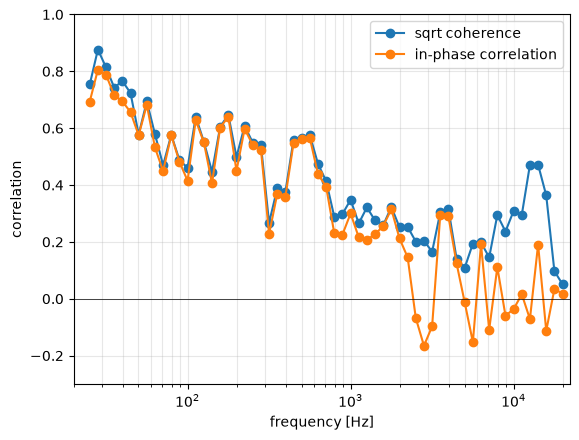

In [5]:
n = 2**16
# look at squared coherence
f_c, C = sp.signal.coherence(y[0], y[1], fs=sr, nperseg=n)
# and cross power spectral density to compute correlation
_, Pxy = sp.signal.csd(y[0], y[1], fs=sr, nperseg=n)
_, Pxx = sp.signal.welch(y[0], fs=sr, nperseg=n)
_, Pyy = sp.signal.welch(y[1], fs=sr, nperseg=n)

# bin it again
per_band = lambda v: sp.stats.binned_statistic(f_c, v, statistic="median", bins=bins)[0]
# this should give similarity at any phase
coh = per_band(C)
# and this should give similarity of phase (signed)
r = per_band(Pxy.real / np.sqrt(Pxx * Pyy))

plt.semilogx(bin_centers[:-1], np.sqrt(coh), "o-", label="sqrt coherence")
plt.semilogx(bin_centers[:-1], r, "o-", label="in-phase correlation")
plt.axhline(0, color="k", lw=0.5)
plt.ylim(-0.3, 1)
plt.xlim(20, sr / 2)
plt.grid(True, which="both", alpha=0.3)
plt.xlabel("frequency [Hz]")
plt.ylabel("correlation")
plt.legend()

In [6]:
def filter_chain(hipass_freq, alpha1, knee1, alpha2, knee2, alpha3, sr=44_100):
    return sos(
        # hi-pass at very low frequencies
        sp.signal.butter(2, hipass_freq, fs=sr, output="sos", btype="highpass"),
        spectral_tilt(4, 50, knee1 - 50, alpha1 / 2, sr),
        spectral_tilt(4, 50, knee1 - 50, alpha1 / 2, sr),
        spectral_tilt(6, knee1, knee2 - knee1, alpha2 / 2, sr),
        spectral_tilt(6, knee1, knee2 - knee1, alpha2 / 2, sr),
        spectral_tilt(6, knee2, 20000 - knee2, alpha3 / 4, sr),
        spectral_tilt(6, knee2, 20000 - knee2, alpha3 / 4, sr),
        spectral_tilt(6, knee2, 20000 - knee2, alpha3 / 4, sr),
        spectral_tilt(6, knee2, 20000 - knee2, alpha3 / 4, sr),
    )


def model(p, f, sr=44_100):
    (
        *chain_params,
        chain_gain,
    ) = p

    # no.noise has a flat power in dB/Hz
    wn = 10 * np.log10(2 / (3 * sr))

    return wn + db_curve(filter_chain(*chain_params), f) + chain_gain

RMS error 6.56 dB
True `ftol` termination condition is satisfied.



Text(0.5, 1.0, 'mean of channels')

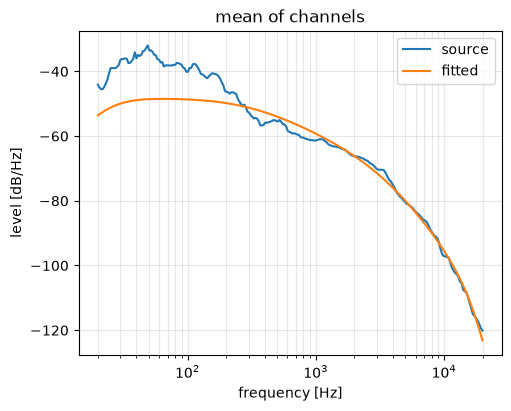

In [7]:
# here fit the spectrum on the average of channel powers, don't share parameters
# (bumps later would fit gain-per-channel and that would give us the stereo effect)


x0 = [35, -0.5, 400, -0.5, 3500, -0.5, -40]
lower = [25, -1.98, 150, -1.98, 1500, -3.98, -80]
upper = [70, 0, 650, 0, 5500, 0, 0]


fit = sp.optimize.least_squares(
    lambda p, t, f: model(p, f) - t,
    x0,
    bounds=(lower, upper),
    x_scale="jac",
    args=(mean_curve, grid),
)


print(f"RMS error {np.sqrt(np.mean(fit.fun**2)):.2f} dB")
print(fit.success, fit.message)
print()

fig, ax = plt.subplots(1, figsize=(5, 4), layout="constrained")
ax.semilogx(grid, mean_curve, label="source")
ax.semilogx(grid, model(fit.x, grid), label="fitted")
ax.grid(True, which="both", alpha=0.3)
ax.set_xlabel("frequency [Hz]")
ax.set_ylabel("level [dB/Hz]")
ax.legend()
ax.set_title("mean of channels")

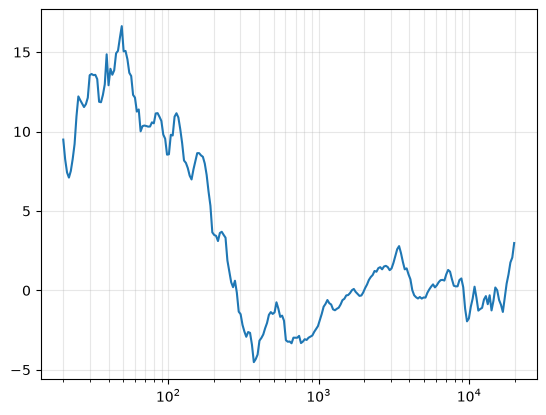

In [8]:
# this is the residual that we can fit with peaking eq filters!
resid = mean_curve - model(fit.x, grid)
plt.semilogx(grid, resid)
plt.grid(True, which="both", alpha=0.3)

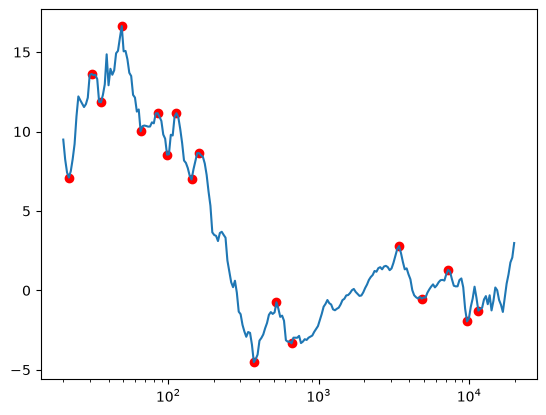

In [9]:
# find positive and negative peaks
bells0 = []
ks = []
for sign in (1, -1):
    k, props = sp.signal.find_peaks(sign * resid, prominence=1, width=3)
    # bandwidth at half prominence
    bw = props["widths"] / 24  # octaves at half prominence
    # bandwidth in octaves to Q unit change
    q = 1 / (2 * np.sinh(np.log(2) / 2 * bw))
    bells0 += zip(grid[k], q, sign * props["prominences"])
    ks.extend(k)
bells0 = np.array(sorted(bells0))

plt.semilogx(grid, resid)
plt.scatter(grid[ks], resid[ks], color="red")

RMS error 0.87 dB
True `ftol` termination condition is satisfied.



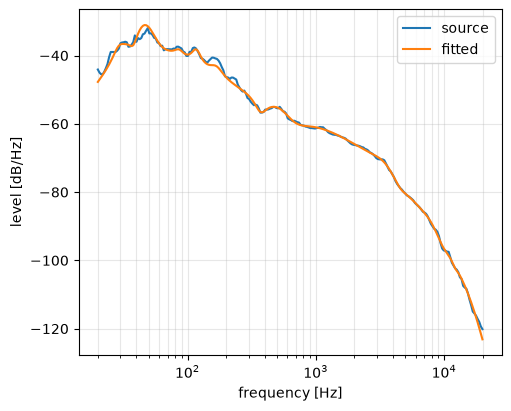

In [10]:
# fit gains, qs, freqs to resid of the mean of channels
def bell_curve(p, f):
    return db_curve(sos(*[bell(fc, q, g) for fc, q, g in np.reshape(p, (-1, 3))]), f)


# bounds are set tight with freq within a tone, q within observed bandwidth
lo = np.ravel([(fc * 2 ** (-1 / 12), q / 2, min(0, 2 * g)) for fc, q, g in bells0])
hi = np.ravel([(fc * 2 ** (1 / 12), q * 2, max(0, 2 * g)) for fc, q, g in bells0])

bell_fit = sp.optimize.least_squares(
    lambda p, t, f: bell_curve(p, f) - t,
    np.ravel(bells0),
    bounds=(lo, hi),
    x_scale="jac",
    args=(resid, grid),
)

print(f"RMS error {np.sqrt(np.mean(bell_fit.fun**2)):.2f} dB")
print(bell_fit.success, bell_fit.message)
print()

# evaluate

fig, ax = plt.subplots(1, figsize=(5, 4), layout="constrained")

ax.semilogx(grid, mean_curve, label="source")
ax.semilogx(grid, model(fit.x, grid) + bell_curve(bell_fit.x, grid), label="fitted")
ax.grid(True, which="both", alpha=0.3)
ax.set_xlabel("frequency [Hz]")
ax.set_ylabel("level [dB/Hz]")
ax.legend()


In [11]:
# now adjust stereo parameters
# keep everything but gains fixed, but adjust gains to match the stereo spectrum better
fc, q, g = np.reshape(bell_fit.x, (-1, 3)).T

# drop bells that go to 0db
keep = np.abs(g) > 0.1
fc, q, g = fc[keep], q[keep], g[keep]

def channel_curve(p, f):
    return p[0] + bell_curve(np.ravel(np.column_stack([fc, q, p[1:]])), f)

lo = np.concatenate([[-20], np.minimum(0, 3 * g)])
hi = np.concatenate([[20], np.maximum(0, 3 * g)])

channel_fits = []
for ch in range(2):
    channel_fit = sp.optimize.least_squares(
        lambda p, t, f: channel_curve(p, f) - t,
        np.concatenate([[0], g]),
        bounds=(lo, hi),
        x_scale="jac",
        args=(floor_curves[ch] - model(fit.x, grid), grid),
    )
    print(f"{'LR'[ch]} channel: RMS error {np.sqrt(np.mean(channel_fit.fun**2)):.2f} dB, offset {channel_fit.x[0]:+.2f} dB")
    channel_fits.append(channel_fit.x)

# finally adjust offsets and save fit...
names = ["hipassFreq", "alpha1", "knee1", "alpha2", "knee2", "alpha3"]

smooth_params = dict(
    zip(names, fit.x[:-1]),
    chainGainL=fit.x[-1] + channel_fits[0][0],
    chainGainR=fit.x[-1] + channel_fits[1][0],
)
pl.DataFrame([smooth_params]).write_csv("../data/room-05-fit.csv")

# and bells
pl.DataFrame({"freq": fc, "q": q, "gainL": channel_fits[0][1:], "gainR": channel_fits[1][1:]}).write_csv("../data/room-05-bells.csv")

L channel: RMS error 1.01 dB, offset -1.50 dB
R channel: RMS error 0.72 dB, offset +1.56 dB


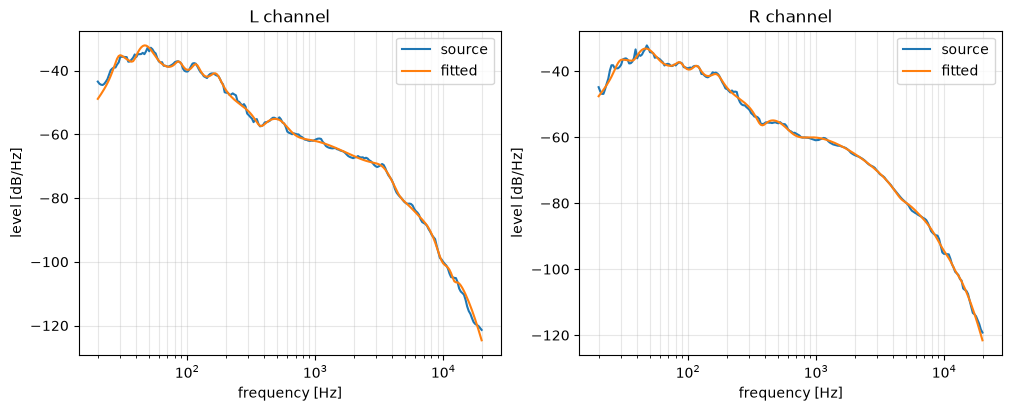

In [12]:
# evaluate stereo match

fig, axs = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ch, ax in enumerate(axs):
    ax.semilogx(grid, floor_curves[ch], label="source")
    ax.semilogx(grid, model(fit.x, grid) + channel_curve(channel_fits[ch], grid), label="fitted")
    ax.grid(True, which="both", alpha=0.3)
    ax.set_xlabel("frequency [Hz]")
    ax.set_ylabel("level [dB/Hz]")
    ax.legend()
    ax.set_title(f"{'LR'[ch]} channel")

this is great and very close to the source, but we are missing dynamics.

the tones are "beating" which suggests modeling them as either variable in frequency, or as a very narrow filter changing parameters.

the second option will actually be more physically correct here

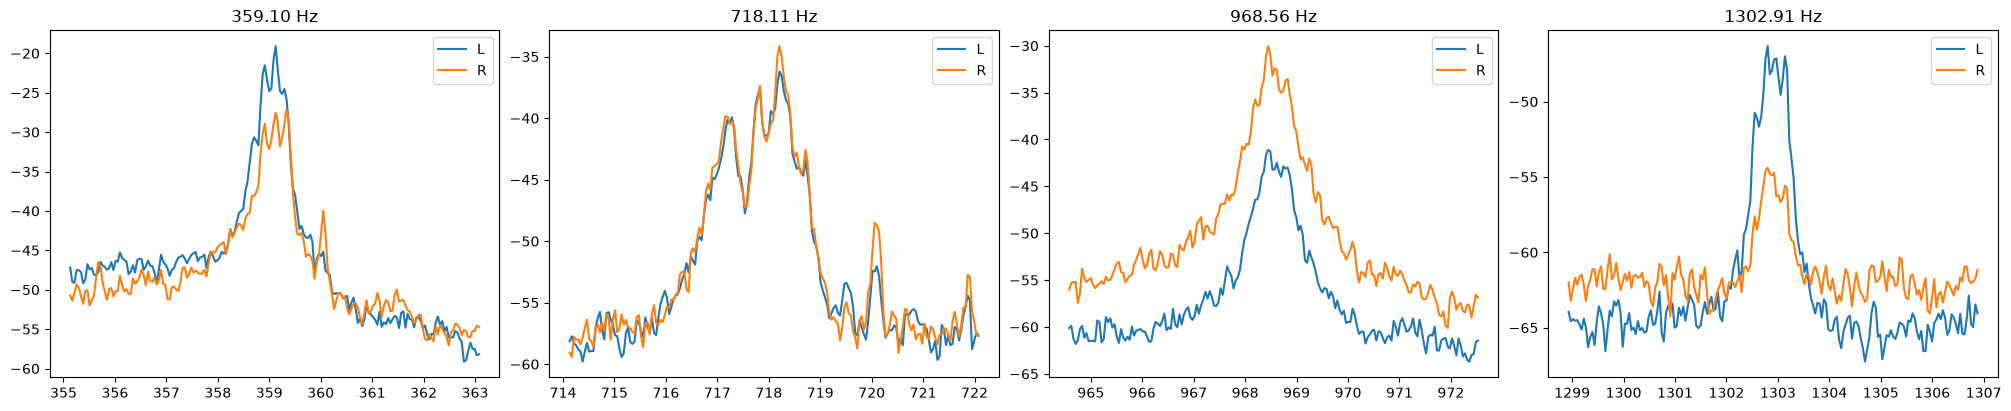

In [13]:
# make a very narrow spectrum at 2**20
f_fine, P_fine = sp.signal.welch(y, fs=sr, window="hann", nperseg=2**20, scaling="density")

# plot the small range around each tone
fig, axs = plt.subplots(1, len(tone_df), figsize=(5 * len(tone_df), 4), layout="constrained")
for ax, t in zip(axs, tone_df["freq"]):
    m = (f_fine > t - 4) & (f_fine < t + 4)
    for ch in range(2):
        ax.plot(f_fine[m], 10 * np.log10(P_fine[ch][m]), label="LR"[ch])
    ax.set_title(f"{t:.2f} Hz")
    ax.legend()

# okay, now modelling them as filtered noise is making all the sense 
# note: there should be a way to conclude statistically if it's noise or oscillator
#  https://faculty.washington.edu/kessler/generals/complex-demodulation.pdf

In [14]:
# now fit the (very resonant) filters

# base power of no.noise in Faust at 44100 
N0 = 2 / (3 * sr)
# frequency step
df = f_fine[1] - f_fine[0]

# find all peaks around the tones
lines = []
for t in tone_df["freq"]:
    # points within 3 Hz of the coarse peak 
    near = (f_fine > t - 3) & (f_fine < t + 3)
    # baseine further away 
    side = ((f_fine > t - 8) & (f_fine < t - 5)) | ((f_fine > t + 5) & (f_fine < t + 8))
    # median baseline per channel
    floor = np.array([np.median(P_fine[ch][side]) for ch in range(2)])
    # excess "up" over baseline
    excess = np.clip(P_fine[:, near] - floor[:, None], 0, None)

    # look for peaks on mean excess (sharing tone freqs as before)
    mean_db = 10 * np.log10(excess.mean(axis=0) + 1e-30)
    # tune these values "by eye"
    #  key is that height is relative to the floor and 
    #  not to max peak height like i tried originally
    k, _ = sp.signal.find_peaks(mean_db, prominence=3, height=10 * np.log10(floor.mean()) + 6)

    # peak boundaries as min points between neighbor found fine peaks
    cuts = [0] + [a + np.argmin(mean_db[a:b]) for a, b in zip(k[:-1], k[1:])] + [len(mean_db)]

    # for each k,
    for j, lo, hi in zip(k, cuts[:-1], cuts[1:]):
        # quad_interp again and record as usual
        # (with freq, Q on mean db still...
        freq, _ = quad_interp(f_fine[near], mean_db, j)
        row, widths = {"freq": freq}, []
        for ch in range(2):
            # ...and gain on each channel)
            peak, power = excess[ch][lo:hi].max(), excess[ch][lo:hi].sum() * df
            widths.append(power / peak)
            row["gain" + "LR"[ch]] = 10 * np.log10(peak / N0)
        row["q"] = np.pi / 2 * freq / np.mean(widths)
        lines.append(row)
# this gives us unit-gain filters that we muiltiply by gain outside of the filter
# (also remove one weak peak with low q)
lines_df = pl.DataFrame(lines).select("freq", "q", "gainL", "gainR").filter(pl.col("q") > 1000)
lines_df.write_csv("../data/room-05-filtertones.csv")

In [15]:
lines_df

freq,q,gainL,gainR
f64,f64,f64,f64
358.908993,3528.087148,26.674335,19.248968
359.119789,2544.828223,29.116287,21.085102
360.048298,2020.962211,2.586939,8.083055
717.196726,2586.453596,8.231741,8.304484
717.817832,6021.485798,10.649686,10.793354
718.211687,3489.90224,11.975345,14.049891
720.079411,3722.965783,-4.855166,-0.716772
968.449502,3008.805601,7.061759,18.158848
1302.792954,3979.204848,1.813482,-7.025735
